# Extended benchmark comparison

Comparison of Greedy, Heuristic, Uniform, and Random on the extended one- and two-dimensional datasets. All errors use exact sequential $P/Q$ outcome probabilities.

In [14]:
# Resolve the project whether Jupyter starts here or from the repository root.
import importlib
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working = Path.cwd().resolve()
PROJECT = working / "problem-2-min-error-seq" if (working / "problem-2-min-error-seq").is_dir() else working
SOURCE = PROJECT / "src"
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

_analysis_module = importlib.reload(importlib.import_module("analysis"))
run_analysis = _analysis_module.run_analysis
_figures_module = importlib.reload(importlib.import_module("figures"))
summary_markdown = _figures_module.summary_markdown
load_summary = _figures_module.load_summary
load_case_rows = _figures_module.load_case_rows


## Settings

Test mode uses 180 deterministic cases per dimension and covers every $(K,M)$ pair. Full mode uses all 2,160 cases per dimension. Saved results are loaded by default; `RUN_ANALYSIS` controls algorithm execution.

In [15]:
# Load saved results by default. Set this to True to run or resume the study.
RUN_ANALYSIS = False

# Use "full" for the complete study after confirming the test run.
RUN_MODE = "full"
RESUME = True
TIME_LIMIT_SECONDS = 30.0

# These controls apply only to the heuristic method.
BEAM_WIDTH = 3
MAX_ITERATIONS = 30

# This notebook is intentionally tied to the extended datasets.
STUDY = "extended"

## Results

Matched method results with checkpoint support.

In [16]:
# Load saved tables unless an algorithm run is explicitly requested.
if RUN_ANALYSIS:
    run_analysis = importlib.reload(importlib.import_module("analysis")).run_analysis
    analysis = run_analysis(
        project=PROJECT,
        study=STUDY,
        mode=RUN_MODE,
        resume=RESUME,
        exact_k_max=4,
        time_limit=TIME_LIMIT_SECONDS,
        beam_width=BEAM_WIDTH,
        max_iterations=MAX_ITERATIONS,
    )
    print("Analysis run requested; algorithms were run or resumed.")
else:
    result_output = PROJECT / "results" / STUDY / RUN_MODE
    try:
        saved_summary = load_summary(PROJECT, STUDY, mode=RUN_MODE)
        saved_rows = load_case_rows(PROJECT, STUDY, mode=RUN_MODE)
    except FileNotFoundError as error:
        raise FileNotFoundError(
            f"Saved {STUDY} {RUN_MODE} results are unavailable. "
            "Set RUN_ANALYSIS = True to generate them."
        ) from error
    analysis = {
        "summary": saved_summary,
        "rows": saved_rows,
        "output": result_output,
    }
    print("Loaded saved results; no allocation algorithms were run.")

# Confirm that this notebook used both extended datasets and the four scalable methods.
expected_datasets = {"benchmark_1d", "benchmark_2d"}
expected_methods = {"Greedy", "Heuristic", "Uniform", "Random"}
observed_datasets = {row["dataset"] for row in analysis["rows"]}
observed_methods = {row["method"] for row in analysis["rows"]}
assert observed_datasets == expected_datasets
assert observed_methods == expected_methods
expected_k = set(range(3, 11))
expected_m = set(range(2, 11))
assert {int(row["K"]) for row in analysis["rows"]} == expected_k
assert {int(row["M"]) for row in analysis["rows"]} == expected_m
assert {(int(row["K"]), int(row["M"])) for row in analysis["rows"]} == {(K, M) for K in expected_k for M in expected_m}

case_counts = {
    dimension: len({
        (row["dataset"], row["case"])
        for row in analysis["rows"]
        if int(row["dimension"]) == dimension
    })
    for dimension in (1, 2)
}
if RUN_MODE == "test":
    assert min(case_counts.values()) >= 180

print("Verified datasets:", sorted(observed_datasets))
print("Verified methods:", sorted(observed_methods))
print("Unique cases by dimension:", case_counts)
print("Results directory:", analysis["output"])

Loaded saved results; no allocation algorithms were run.
Verified datasets: ['benchmark_1d', 'benchmark_2d']
Verified methods: ['Greedy', 'Heuristic', 'Random', 'Uniform']
Unique cases by dimension: {1: 2160, 2: 2160}
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/problem-2-min-error-seq/results/extended/full


## Completion summary

Method status counts and matched error summaries.

In [17]:
# Report method completion before displaying aggregate values.
from collections import Counter

completion = Counter((row["method"], row["status"]) for row in analysis["rows"])
print("Method-status counts:", completion)
display(Markdown(summary_markdown(analysis["summary"])))

Method-status counts: Counter({('Greedy', 'ok'): 17211, ('Uniform', 'ok'): 17211, ('Random', 'ok'): 17211, ('Heuristic', 'ok'): 17171, ('Heuristic', 'timeout'): 40})


| Dimension | Budget | Method | Cases | Mean Error Probability | Mean Time (s) | Mean Gap |
|---|---:|---|---:|---:|---:|---:|
| One-dimensional | 1 | Greedy | 2158 | 0.46805 | 0.0084 | — |
| One-dimensional | 1 | Heuristic | 2158 | 0.27825 | 0.6274 | — |
| One-dimensional | 1 | Random | 2158 | 0.69251 | 0.0047 | — |
| One-dimensional | 1 | Uniform | 2158 | 0.68378 | 0.0048 | — |
| One-dimensional | 2 | Greedy | 2157 | 0.33382 | 0.0096 | — |
| One-dimensional | 2 | Heuristic | 2157 | 0.11412 | 0.6353 | — |
| One-dimensional | 2 | Random | 2157 | 0.60072 | 0.0048 | — |
| One-dimensional | 2 | Uniform | 2157 | 0.58305 | 0.0048 | — |
| One-dimensional | 3 | Greedy | 2150 | 0.23790 | 0.0110 | — |
| One-dimensional | 3 | Heuristic | 2150 | 0.03986 | 0.6266 | — |
| One-dimensional | 3 | Random | 2150 | 0.52613 | 0.0048 | — |
| One-dimensional | 3 | Uniform | 2150 | 0.50282 | 0.0048 | — |
| One-dimensional | 4 | Greedy | 2122 | 0.17990 | 0.0125 | — |
| One-dimensional | 4 | Heuristic | 2122 | 0.01762 | 0.6967 | — |
| One-dimensional | 4 | Random | 2122 | 0.47199 | 0.0049 | — |
| One-dimensional | 4 | Uniform | 2122 | 0.44719 | 0.0049 | — |
| Two-dimensional | 1 | Greedy | 2156 | 0.46518 | 0.0081 | — |
| Two-dimensional | 1 | Heuristic | 2156 | 0.31269 | 0.5770 | — |
| Two-dimensional | 1 | Random | 2156 | 0.70872 | 0.0046 | — |
| Two-dimensional | 1 | Uniform | 2156 | 0.70081 | 0.0047 | — |
| Two-dimensional | 2 | Greedy | 2148 | 0.33170 | 0.0095 | — |
| Two-dimensional | 2 | Heuristic | 2148 | 0.14209 | 0.6188 | — |
| Two-dimensional | 2 | Random | 2148 | 0.62736 | 0.0046 | — |
| Two-dimensional | 2 | Uniform | 2148 | 0.61560 | 0.0046 | — |
| Two-dimensional | 3 | Greedy | 2155 | 0.23484 | 0.0111 | — |
| Two-dimensional | 3 | Heuristic | 2155 | 0.05955 | 0.6329 | — |
| Two-dimensional | 3 | Random | 2155 | 0.55897 | 0.0047 | — |
| Two-dimensional | 3 | Uniform | 2155 | 0.54588 | 0.0047 | — |
| Two-dimensional | 4 | Greedy | 2125 | 0.17632 | 0.0127 | — |
| Two-dimensional | 4 | Heuristic | 2125 | 0.03371 | 0.6474 | — |
| Two-dimensional | 4 | Random | 2125 | 0.51656 | 0.0048 | — |
| Two-dimensional | 4 | Uniform | 2125 | 0.49421 | 0.0048 | — |

## Mean runtime

Mean runtime by dimension, $K$, and method for completed matched evaluations.

In [18]:
from collections import defaultdict
from statistics import fmean

def mean_runtime_table(rows):
    matched = _figures_module._matched_rows(rows)
    methods = [
        method for method in _figures_module.STYLES
        if any(row["method"] == method for row in matched)
    ]
    grouped = defaultdict(list)
    for row in matched:
        grouped[(int(row["dimension"]), int(row["K"]), row["method"])].append(
            float(row["seconds"])
        )

    table = []
    for dimension in (1, 2):
        K_values = sorted({
            int(row["K"]) for row in matched
            if int(row["dimension"]) == dimension
        })
        for K in K_values:
            row = {"dimension": dimension, "K": K}
            counts = []
            for method in methods:
                values = grouped[(dimension, K, method)]
                row[f"{method.lower()}_mean_seconds"] = fmean(values)
                counts.append(len(values))
            if len(set(counts)) != 1:
                raise RuntimeError(
                    f"Runtime comparison is not matched for dimension={dimension}, K={K}"
                )
            row["runs_per_method"] = counts[0]
            table.append(row)
    return table, methods


def runtime_markdown(rows, methods):
    headings = ["Dimension", "K", "Runs per method", *methods]
    lines = [
        "| " + " | ".join(headings) + " |",
        "|" + "|".join("---:" for _ in headings) + "|",
    ]
    for row in rows:
        values = [f"{row['dimension']}D", str(row["K"]), str(row["runs_per_method"])]
        values.extend(
            f"{row[f'{method.lower()}_mean_seconds']:.5f}"
            for method in methods
        )
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)


runtime_rows, runtime_methods = mean_runtime_table(analysis["rows"])
_analysis_module.write_csv(
    analysis["output"] / "tables" / "mean_runtime.csv",
    runtime_rows,
)
display(Markdown(runtime_markdown(runtime_rows, runtime_methods)))

| Dimension | K | Runs per method | Greedy | Heuristic | Uniform | Random |
|---:|---:|---:|---:|---:|---:|---:|
| 1D | 3 | 1046 | 0.00034 | 0.00244 | 0.00011 | 0.00010 |
| 1D | 4 | 1076 | 0.00087 | 0.00742 | 0.00022 | 0.00021 |
| 1D | 5 | 1080 | 0.00184 | 0.01631 | 0.00046 | 0.00045 |
| 1D | 6 | 1080 | 0.00360 | 0.03616 | 0.00101 | 0.00099 |
| 1D | 7 | 1080 | 0.00658 | 0.10886 | 0.00221 | 0.00218 |
| 1D | 8 | 1080 | 0.01192 | 0.27345 | 0.00486 | 0.00478 |
| 1D | 9 | 1080 | 0.02236 | 1.06858 | 0.01057 | 0.01066 |
| 1D | 10 | 1065 | 0.03538 | 3.67659 | 0.01921 | 0.01912 |
| 2D | 3 | 1050 | 0.00035 | 0.00298 | 0.00008 | 0.00008 |
| 2D | 4 | 1079 | 0.00085 | 0.00757 | 0.00017 | 0.00017 |
| 2D | 5 | 1080 | 0.00182 | 0.01710 | 0.00037 | 0.00037 |
| 2D | 6 | 1080 | 0.00342 | 0.03477 | 0.00081 | 0.00080 |
| 2D | 7 | 1080 | 0.00609 | 0.07611 | 0.00177 | 0.00178 |
| 2D | 8 | 1079 | 0.01064 | 0.22647 | 0.00389 | 0.00385 |
| 2D | 9 | 1078 | 0.01902 | 0.81844 | 0.00852 | 0.00861 |
| 2D | 10 | 1058 | 0.04094 | 3.81515 | 0.02212 | 0.02198 |

## Comparison figures

Mean error by budget fraction, allocation agreement by $K$, and field-family error with instance-level 95% confidence intervals.

### Error Probability

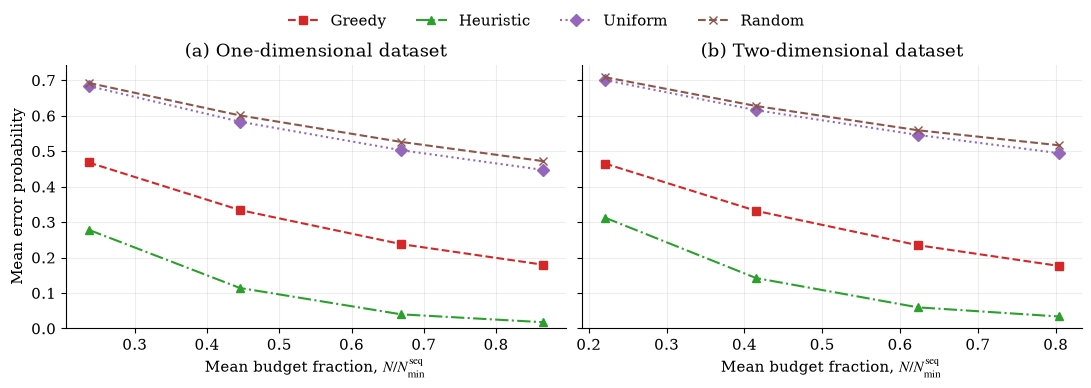

### Allocation Match

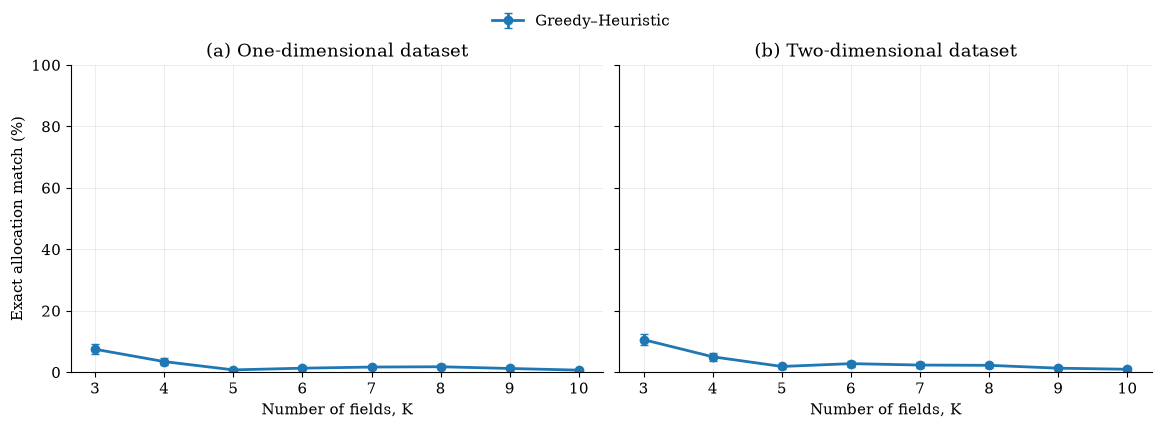

### Error By Field Family

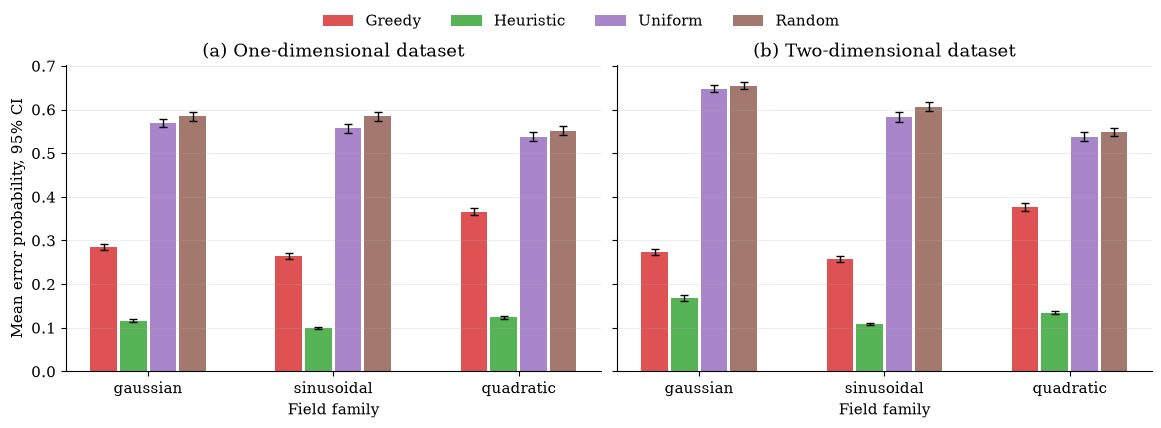

In [19]:
# Save and display the requested figures. Runtime is table-only.
from collections import defaultdict
from statistics import fmean
_figures_module = importlib.reload(importlib.import_module("figures"))


def instance_averaged_error_rows(rows):
    grouped = defaultdict(list)
    metadata = {}
    for row in _figures_module._matched_rows(rows):
        key = (row["dataset"], row["case"], row["method"])
        grouped[key].append(_figures_module._error(row))
        metadata[key] = row

    averaged = []
    for key, values in grouped.items():
        row = dict(metadata[key])
        mean_error = fmean(values)
        row["N"] = 0
        row["actual_error"] = mean_error
        row["error_probability"] = mean_error
        averaged.append(row)
    return averaged

if not analysis["summary"]:
    raise RuntimeError("No matched completed cases are available for plotting")

figures = {
    "error_probability": _figures_module.plot_mean_error(analysis["summary"]),
    "allocation_match": _figures_module.plot_allocation_match(analysis["rows"]),
    "error_by_field_family": _figures_module.plot_error_by_family(
        instance_averaged_error_rows(analysis["rows"])
    ),
}
figure_directory = analysis["output"] / "figures"
figure_directory.mkdir(parents=True, exist_ok=True)
for obsolete_name in ("runtime_by_k", "runtime_boxplot", "seconds"):
    for extension in ("pdf", "png"):
        (figure_directory / f"{obsolete_name}.{extension}").unlink(missing_ok=True)
for name, figure in figures.items():
    for extension in ("pdf", "png"):
        figure.savefig(
            figure_directory / f"{name}.{extension}",
            dpi=300,
            bbox_inches="tight",
        )
    display(Markdown(f"### {name.replace('_', ' ').title()}"))
    display(figure)
    plt.close(figure)
